In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from joblib import Parallel, delayed, parallel_config

from debug.qm_env_plots import plot_results
from serialization.serialize_experiment import load_experiment, read_experiment_metadata
from utils.evaluate import get_control_sequence


In [2]:
EXPERIMENT_ID = "2026-11-16T20-54-35-535476Z"

metadata = read_experiment_metadata(EXPERIMENT_ID)

ENV_PARAMS = metadata["env_params"]
HYPER_PARAMS = metadata["hyper_params"]

seed = metadata["seed"]

In [3]:
agent, gym_env, _ = load_experiment(EXPERIMENT_ID)

env = gym_env.qm_env

In [4]:
histories = []

def replay():

    _, actions, _ = get_control_sequence(
        gym_env, 
        agent, 
        seed = seed, 
        deterministic=False
    )

    return env.replay(actions)

with parallel_config(
    backend="loky",
    n_jobs=14,
    inner_max_num_threads=1
):
    histories = Parallel(verbose=10)(
        delayed(replay)()
        for _ in range(50)
    )

[Parallel(n_jobs=14)]: Using backend LokyBackend with 14 concurrent workers.
[Parallel(n_jobs=14)]: Done   4 tasks      | elapsed:    7.0s
[Parallel(n_jobs=14)]: Done  13 tasks      | elapsed:    7.3s
[Parallel(n_jobs=14)]: Done  22 tasks      | elapsed:    9.1s
[Parallel(n_jobs=14)]: Done  29 out of  50 | elapsed:   10.1s remaining:    7.3s
[Parallel(n_jobs=14)]: Done  35 out of  50 | elapsed:   10.7s remaining:    4.5s
[Parallel(n_jobs=14)]: Done  41 out of  50 | elapsed:   10.9s remaining:    2.3s
[Parallel(n_jobs=14)]: Done  47 out of  50 | elapsed:   11.8s remaining:    0.7s
[Parallel(n_jobs=14)]: Done  50 out of  50 | elapsed:   12.0s finished


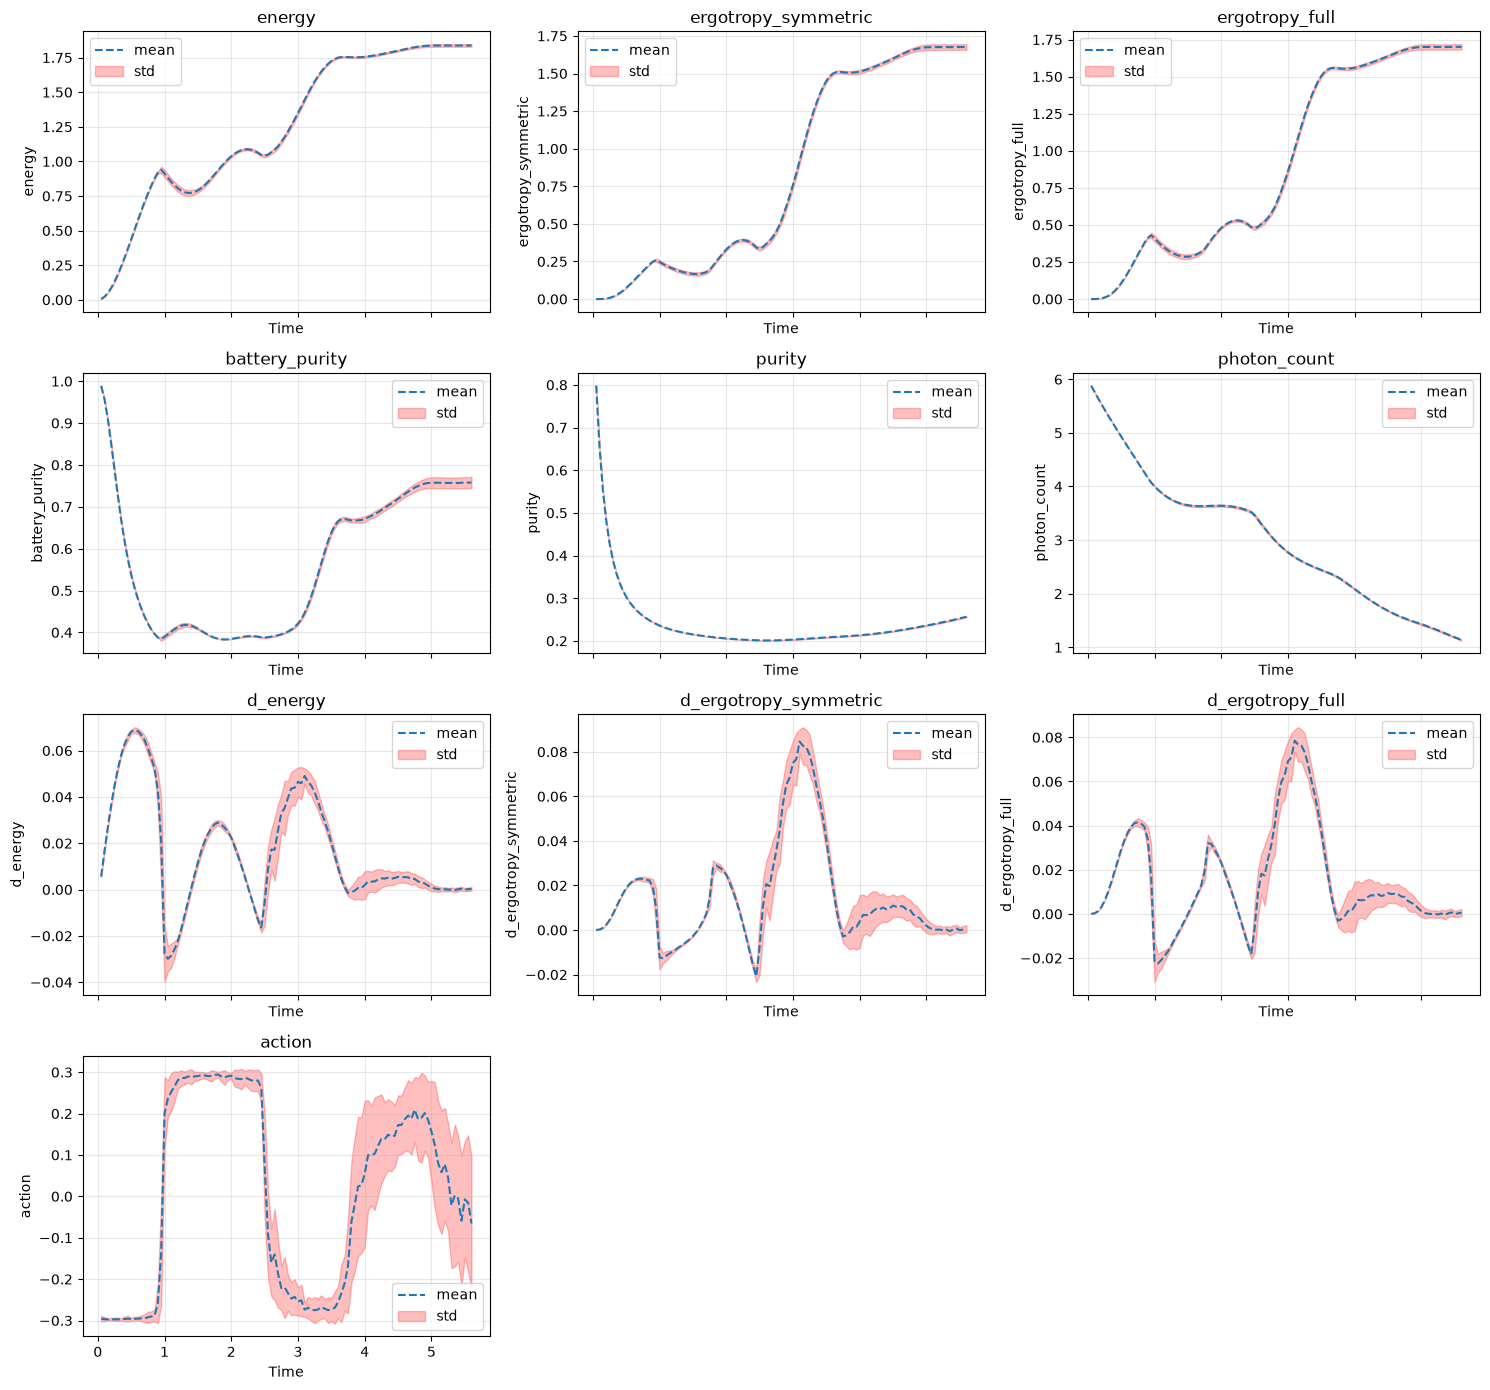

In [5]:
plot_results(histories)